# Diagnosing the ST-GNN advantage (Colab)

Uses original labels and the already audited Test 2 checkpoints. It compares the same flows for ST-GNN, Static GNN, and Edge GRU without assigning attack stages, tactics, or IPs. It also performs an **exploratory intervention**: resetting ST-GNN memory before every window without retraining. This tests checkpoint sensitivity to history, but does not establish a general causal contribution. Existing artifacts are not modified.


In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec('torch_geometric') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'torch_geometric'], check=True)
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
DRIVE_ROOT = Path('/content/drive/MyDrive/nids-mitre')
RESULTS = DRIVE_ROOT / 'results_earlystopping'
GRAPH_ROOT = DRIVE_ROOT / 'dataset_processed_thu0103'
CLONE_DIR = Path('/content/temporalgnn-nids-mechanism')
BRANCH = 'feat/fair-comparison-experiments'
EXPECTED_COMMIT = '2262b53d155f9e8cf5221516f47e4170e6cd0d6e'
assert RESULTS.is_dir() and (GRAPH_ROOT / 'test2').is_dir()
if not CLONE_DIR.exists():
    subprocess.run(['git', 'clone', '--depth', '1', '--branch', BRANCH,
                    'https://github.com/tatipar/temporalgnn-nids.git', str(CLONE_DIR)], check=True)
subprocess.run(
    ['git', '-C', str(CLONE_DIR), 'fetch', '--depth', '1', 'origin', EXPECTED_COMMIT],
    check=True,
)
subprocess.run(
    ['git', '-C', str(CLONE_DIR), 'checkout', '--detach', EXPECTED_COMMIT],
    check=True,
)
commit = subprocess.check_output(['git', '-C', str(CLONE_DIR), 'rev-parse', 'HEAD'], text=True).strip()
assert commit == EXPECTED_COMMIT, f'Code commit changed: {commit}; expected {EXPECTED_COMMIT}'
sys.path.insert(0, str(CLONE_DIR / 'code/python'))
print('Pinned code:', commit)


Mounted at /content/drive
Pinned code: 2262b53d155f9e8cf5221516f47e4170e6cd0d6e


In [2]:
import gc, json
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import torch
from torch_geometric.loader import DataLoader
from sklearn.metrics import average_precision_score
from IPython.display import display
from utils.datasets import NF_IDS_Dataset
from utils.models import ST_GNN_Identity, StaticGNN_Identity, EdgeGRU_Baseline_NoX
from utils.metrics import calculate_metrics_gnn

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PARAMS = dict(node_dim=16, edge_dim=32, hidden_dim=32, dropout=0.2,
              output_bias_init=-2.9968)
SPECS = {
    'ST-GNN': ('ST_GNN_BiasOn_robust_Identity_clone', ST_GNN_Identity, 42, True),
    'Static GNN': ('StaticGNN_BiasOn_robust_Identity', StaticGNN_Identity, 42, False),
    'Edge GRU': ('EdgeGRU_NoX_BiasOn', EdgeGRU_Baseline_NoX, 99, True),
}
DATASET = NF_IDS_Dataset(root_dir=str(GRAPH_ROOT), split='test2')
assert len(DATASET) == 2822, f'Expected 2,822 graphs; found {len(DATASET)}'
print('Device:', DEVICE, '| graph files:', len(DATASET))

def artifact(name):
    exp, cls, expected_seed, temporal = SPECS[name]
    old_path = RESULTS / 'test2_results' / f'test2_metrics_{exp}.csv'
    old = pd.read_csv(old_path)
    assert len(old) == 1 and int(old.iloc[0]['seed']) == expected_seed
    old = old.iloc[0]
    run_id = str(old['run_id'])
    hits = list((RESULTS / 'saved_models' / exp).glob(f'{run_id}_*.pth'))
    assert len(hits) == 1, f'Ambiguous checkpoint for {run_id}: {hits}'
    with np.load(RESULTS / 'logs' / exp / f'thresholds_{exp}.npz') as ths:
        th = float(ths[f'seed_{expected_seed}'])
    return dict(name=name, experiment=exp, cls=cls, temporal=temporal,
                seed=expected_seed, run_id=run_id, checkpoint=hits[0],
                threshold=th, old=old)

ARTIFACTS = {name: artifact(name) for name in SPECS}
display(pd.DataFrame([
    {k: v for k, v in a.items() if k in ('name','experiment','seed','run_id','threshold')}
    for a in ARTIFACTS.values()
]))


Device: cpu | graph files: 2822


,name,experiment,seed,run_id,threshold
0,ST-GNN,ST_GNN_BiasOn_robust_Identity_clone,42,ST_GNN_BiasOn_robust_Identity_clone_seed42_202...,0.203219
1,Static GNN,StaticGNN_BiasOn_robust_Identity,42,StaticGNN_BiasOn_robust_Identity_seed42_202602...,0.393601
2,Edge GRU,EdgeGRU_NoX_BiasOn,99,EdgeGRU_NoX_BiasOn_seed99_20260419_205758,0.350914


## 1. Aligned inference and memory sensitivity

The first three passes follow the original protocol. The fourth uses **the same ST-GNN checkpoint** but clears its memory before every window. Its AP is informative; F1 at the original threshold is descriptive because the score distribution changes.


In [4]:
@torch.no_grad()
def score_model(name, reset_each_window=False, capture_meta=False):
    a = ARTIFACTS[name]
    model = a['cls'](**PARAMS).to(DEVICE)
    state = torch.load(a['checkpoint'], map_location=DEVICE, weights_only=True)
    model.load_state_dict(state, strict=True)
    model.eval()
    if hasattr(model, 'reset_memory'):
        model.reset_memory()
    loader = DataLoader(DATASET, batch_size=1, shuffle=False, num_workers=0)
    ys, ps, wins = [], [], []
    meta = {'source_gid':[], 'out_degree':[], 'prior_windows':[]} if capture_meta else None
    seen = {}
    for batch_idx, data in enumerate(loader):
        if data.x.shape[0] == 0:
            continue
        window_id = int(Path(DATASET.files[batch_idx]).stem.split('_')[1])
        y = data.y.cpu().numpy().astype(np.uint8)
        if capture_meta:
            src = data.edge_index[0].cpu().numpy()
            gids = data.global_node_ids.cpu().numpy()
            degrees = np.bincount(src, minlength=len(gids))[src].astype(np.int32)
            prior_nodes = np.fromiter((seen.get(int(g), 0) for g in gids),
                                      dtype=np.int32, count=len(gids))
            meta['source_gid'].append(gids[src].astype(np.int64))
            meta['out_degree'].append(degrees)
            meta['prior_windows'].append(prior_nodes[src])
            for g in gids:
                key = int(g)
                seen[key] = seen.get(key, 0) + 1
        if reset_each_window:
            model.reset_memory()
        data = data.to(DEVICE)
        if a['temporal']:
            logits = model(data.x, data.edge_index, data.edge_attr, data.global_node_ids)
        else:
            logits = model(data.x, data.edge_index, data.edge_attr)
        p = torch.sigmoid(logits.view(-1)).cpu().numpy().astype(np.float32)
        ys.append(y)
        ps.append(p)
        wins.append(np.full(len(y), window_id, dtype=np.int32))
    y = np.concatenate(ys)
    p = np.concatenate(ps)
    win = np.concatenate(wins)
    metrics = calculate_metrics_gnn(y, p, prob_threshold=a['threshold'])
    if meta is not None:
        meta = {k: np.concatenate(chunks) for k, chunks in meta.items()}
    del model, state
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return dict(y=y, p=p, window=win, pred=p > a['threshold'],
                metrics=metrics, meta=meta)

RUNS = {}
for name in SPECS:
    print('Inference:', name)
    result = score_model(name, capture_meta=(name == 'ST-GNN'))
    a = ARTIFACTS[name]
    for metric in ('F1', 'AUC-PR', 'Precision', 'Recall', 'TP', 'FP', 'TN', 'FN'):
        new, old = result['metrics'][metric], a['old'][metric]
        assert np.isclose(new, old, rtol=1e-4, atol=1e-4), (
            f'{name}: {metric}={new}, earlier CSV={old}')
    if RUNS:
        assert np.array_equal(result['y'], RUNS['ST-GNN']['y'])
        assert np.array_equal(result['window'], RUNS['ST-GNN']['window'])
    RUNS[name] = result
    print('  Reproduced Test 2:', len(result['y']), 'flows; AP',
          round(result['metrics']['AUC-PR'], 4), 'F1', round(result['metrics']['F1'], 4))
print('Inference: ST-GNN with memory reset before every window')
RUNS['ST-GNN with reset memory (intervention)'] = score_model('ST-GNN', reset_each_window=True)
assert np.array_equal(RUNS['ST-GNN with reset memory (intervention)']['y'], RUNS['ST-GNN']['y'])
assert np.array_equal(RUNS['ST-GNN with reset memory (intervention)']['window'], RUNS['ST-GNN']['window'])


Inference: ST-GNN
  Reproduced Test 2: 2135957 flows; AP 0.8384 F1 0.7576
Inference: Static GNN
  Reproduced Test 2: 2135957 flows; AP 0.3142 F1 0.2944
Inference: Edge GRU
  Reproduced Test 2: 2135957 flows; AP 0.7307 F1 0.6502
Inference: ST-GNN with memory reset before every window


## 2. Where ST-GNN gains

The comparison pairs predictions for **the same flow** across models and separates exclusive true positives from exclusive false positives. It then stratifies by the source's outgoing degree **in the current window** and by the number of earlier windows in which that node appeared. These are descriptive associations: current volume, history, and other attributes may be correlated.


In [5]:
y = RUNS['ST-GNN']['y']
meta = RUNS['ST-GNN']['meta']
rows = []
for name, r in RUNS.items():
    m = r['metrics']
    rows.append(dict(model=name, flows=len(y), AP=m['AUC-PR'], F1=m['F1'],
                     precision=m['Precision'], recall=m['Recall'], FPR=m['FPR'],
                     TP=m['TP'], FP=m['FP']))
summary = pd.DataFrame(rows)
display(summary.round(4))

st = RUNS['ST-GNN']['pred']
pair_rows = []
for name in ('Static GNN', 'Edge GRU'):
    other = RUNS[name]['pred']
    pos, neg = y == 1, y == 0
    only_st_tp = pos & st & ~other
    only_other_tp = pos & ~st & other
    only_st_fp = neg & st & ~other
    only_other_fp = neg & ~st & other
    ids = pd.Series(meta['source_gid'][only_st_tp]).value_counts()
    pair_rows.append(dict(comparator=name,
                          both_TP=int((pos & st & other).sum()),
                          ST_only_TP=int(only_st_tp.sum()),
                          other_only_TP=int(only_other_tp.sum()),
                          neither_TP=int((pos & ~st & ~other).sum()),
                          ST_only_FP=int(only_st_fp.sum()),
                          other_only_FP=int(only_other_fp.sum()),
                          ST_only_TP_top1_source_share=(float(ids.iloc[0] / ids.sum())
                                                        if len(ids) else np.nan),
                          ST_only_TP_top10_source_share=(float(ids.iloc[:10].sum() / ids.sum())
                                                         if len(ids) else np.nan)))
pairs = pd.DataFrame(pair_rows)
display(pairs.round(4))

prior = meta['prior_windows']
degree = meta['out_degree']
prior_bins = np.select([prior == 0, prior <= 2, prior <= 9],
                       ['0', '1-2', '3-9'], default='10+')
degree_bins = np.select([degree == 1, degree <= 4, degree <= 19],
                        ['1', '2-4', '5-19'], default='20+')

def group_report(values, variable, categories):
    rows = []
    for category in categories:
        ix = values == category
        npos = int((y[ix] == 1).sum())
        nneg = int((y[ix] == 0).sum())
        row = dict(variable=variable, group=category, flows=int(ix.sum()),
                   attacks=npos, benign=nneg)
        for name in ('ST-GNN', 'Static GNN', 'Edge GRU'):
            pred = RUNS[name]['pred'][ix]
            prob = RUNS[name]['p'][ix]
            row[f'{name}_recall'] = float(pred[y[ix] == 1].mean()) if npos else np.nan
            row[f'{name}_FPR'] = float(pred[y[ix] == 0].mean()) if nneg else np.nan
            row[f'{name}_AP'] = (float(average_precision_score(y[ix], prob))
                                  if npos and nneg else np.nan)
        rows.append(row)
    return rows

prior_categories = ['0','1-2','3-9','10+']
degree_categories = ['1','2-4','5-19','20+']
joint_bins = np.char.add(np.char.add(prior_bins, ' / '), degree_bins)
joint_categories = [p + ' / ' + d for p in prior_categories for d in degree_categories]
grouped = pd.DataFrame(
    group_report(prior_bins, 'previous source windows', prior_categories)
    + group_report(degree_bins, 'outgoing edges in current window', degree_categories)
    + group_report(joint_bins, 'history / outgoing degree', joint_categories)
)
display(grouped.round(4))


,model,flows,AP,F1,precision,recall,FPR,TP,FP
0,ST-GNN,2135957,0.8384,0.7576,0.6336,0.9419,0.0278,97793,56546
1,Static GNN,2135957,0.3142,0.2944,0.5094,0.2071,0.0102,21497,20707
2,Edge GRU,2135957,0.7307,0.6502,0.5990,0.7110,0.0243,73819,49410
3,ST-GNN with reset memory (intervention),2135957,0.4507,0.2813,0.9270,0.1658,0.0007,17217,1355


,comparator,both_TP,ST_only_TP,other_only_TP,neither_TP,ST_only_FP,other_only_FP,ST_only_TP_top1_source_share,ST_only_TP_top10_source_share
0,Static GNN,20871,76922,626,5406,52930,17091,0.4040,0.9562
1,Edge GRU,72235,25558,1584,4448,16363,9227,0.8729,0.9860


,variable,group,flows,attacks,benign,ST-GNN_recall,ST-GNN_FPR,ST-GNN_AP,Static GNN_recall,Static GNN_FPR,Static GNN_AP,Edge GRU_recall,Edge GRU_FPR,Edge GRU_AP
0,previous source windows,0,46103,516,45587,0.1124,0.0024,0.1331,0.4671,0.0063,0.2685,0.1182,0.0082,0.1850
1,previous source windows,1-2,45080,281,44799,0.2740,0.0024,0.2370,0.1886,0.0084,0.0409,0.2100,0.0089,0.1541
2,previous source windows,3-9,76559,707,75852,0.7086,0.0033,0.5286,0.6888,0.0108,0.3204,0.6605,0.0065,0.5737
3,previous source windows,10+,1968215,102321,1865894,0.9495,0.0301,0.8434,0.2025,0.0103,0.3197,0.7157,0.0258,0.7361
4,outgoing edges in current window,1,103898,240,103658,0.4458,0.0044,0.2221,0.2875,0.0032,0.0638,0.5750,0.0013,0.5372
5,outgoing edges in current window,2-4,257246,5492,251754,0.8312,0.0092,0.7287,0.4040,0.0059,0.3551,0.7631,0.0088,0.7240
6,outgoing edges in current window,5-19,592161,13503,578658,0.9293,0.0101,0.7838,0.2302,0.0074,0.2003,0.9207,0.0113,0.7707
7,outgoing edges in current window,20+,1182652,84590,1098062,0.9525,0.0436,0.8570,0.1903,0.0133,0.3331,0.6745,0.0369,0.7267
8,history / outgoing degree,0 / 1,19723,3,19720,0.0000,0.0003,0.0385,0.0000,0.0020,0.0008,0.0000,0.0001,0.0526
9,history / outgoing degree,0 / 2-4,14666,205,14461,0.2439,0.0058,0.2958,0.0098,0.0030,0.0872,0.0878,0.0033,0.1770


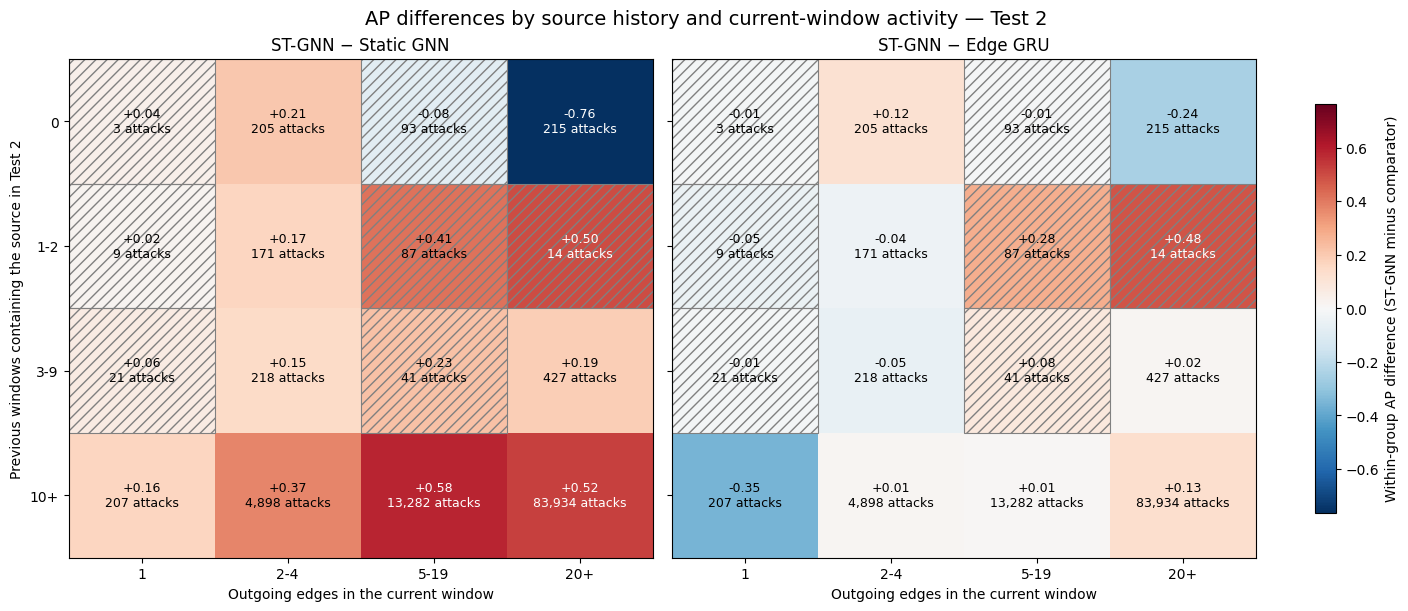

Hatched cells contain fewer than 100 attack-labeled flows.
Figure saved to: /content/drive/MyDrive/nids-mitre/results_comparison/stgnn_gain_audit


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle

history_order = ['0', '1-2', '3-9', '10+']
degree_order = ['1', '2-4', '5-19', '20+']
low_support_cutoff = 100  # visual warning only; cells remain in the figure

# Select the 16 joint history × degree groups from the last table.
joint = grouped.loc[
    grouped['group'].astype(str).str.contains(' / ', regex=False)
].copy()

joint[['history_bin', 'degree_bin']] = joint['group'].astype(str).str.split(
    ' / ', n=1, expand=True
)

assert len(joint) == 16, f'Expected 16 joint groups, found {len(joint)}'
assert not joint.duplicated(['history_bin', 'degree_bin']).any()
assert set(joint['history_bin']) == set(history_order)
assert set(joint['degree_bin']) == set(degree_order)

def as_grid(column):
    return (
        joint.pivot(
            index='history_bin',
            columns='degree_bin',
            values=column,
        )
        .reindex(index=history_order, columns=degree_order)
        .to_numpy(dtype=float)
    )

attack_counts = as_grid('attacks')
st_ap = as_grid('ST-GNN_AP')

comparators = [
    ('Static GNN', st_ap - as_grid('Static GNN_AP')),
    ('Edge GRU', st_ap - as_grid('Edge GRU_AP')),
]

# Both panels use the same color scale, centered on zero.
all_differences = np.stack([difference for _, difference in comparators])
color_limit = max(float(np.nanmax(np.abs(all_differences))), 1e-6)
norm = TwoSlopeNorm(
    vmin=-color_limit,
    vcenter=0,
    vmax=color_limit,
)

fig, axes = plt.subplots(
    1, 2, figsize=(14, 6), sharex=True, sharey=True,
    constrained_layout=True,
)

for ax, (comparator, difference) in zip(axes, comparators):
    image = ax.imshow(
        difference,
        cmap='RdBu_r',
        norm=norm,
        aspect='auto',
    )

    ax.set_title(f'ST-GNN − {comparator}')
    ax.set_xticks(range(len(degree_order)), degree_order)
    ax.set_yticks(range(len(history_order)), history_order)
    ax.set_xlabel('Outgoing edges in the current window')

    for row in range(len(history_order)):
        for col in range(len(degree_order)):
            value = difference[row, col]
            attacks = int(attack_counts[row, col])

            if np.isfinite(value):
                text_color = (
                    'white' if abs(value) > 0.55 * color_limit else 'black'
                )
                label = f'{value:+.2f}\n{attacks:,} attacks'
            else:
                text_color = 'black'
                label = f'AP undefined\n{attacks:,} attacks'

            ax.text(
                col, row, label,
                ha='center', va='center',
                fontsize=9, color=text_color,
            )

            if attacks < low_support_cutoff:
                ax.add_patch(Rectangle(
                    (col - 0.5, row - 0.5), 1, 1,
                    fill=False, hatch='///',
                    edgecolor='gray', linewidth=0.8,
                ))

axes[0].set_ylabel('Previous windows containing the source in Test 2')

fig.colorbar(
    image, ax=axes, shrink=0.82,
    label='Within-group AP difference (ST-GNN minus comparator)',
)
fig.suptitle(
    'AP differences by source history and current-window activity — Test 2',
    fontsize=14,
)

plot_dir = DRIVE_ROOT / 'results_comparison' / 'stgnn_gain_audit'
plot_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(plot_dir / 'ap_history_degree_test2.png',
            dpi=300, bbox_inches='tight')
fig.savefig(plot_dir / 'ap_history_degree_test2.pdf',
            bbox_inches='tight')
plt.show()

print('Hatched cells contain fewer than 100 attack-labeled flows.')
print('Figure saved to:', plot_dir)

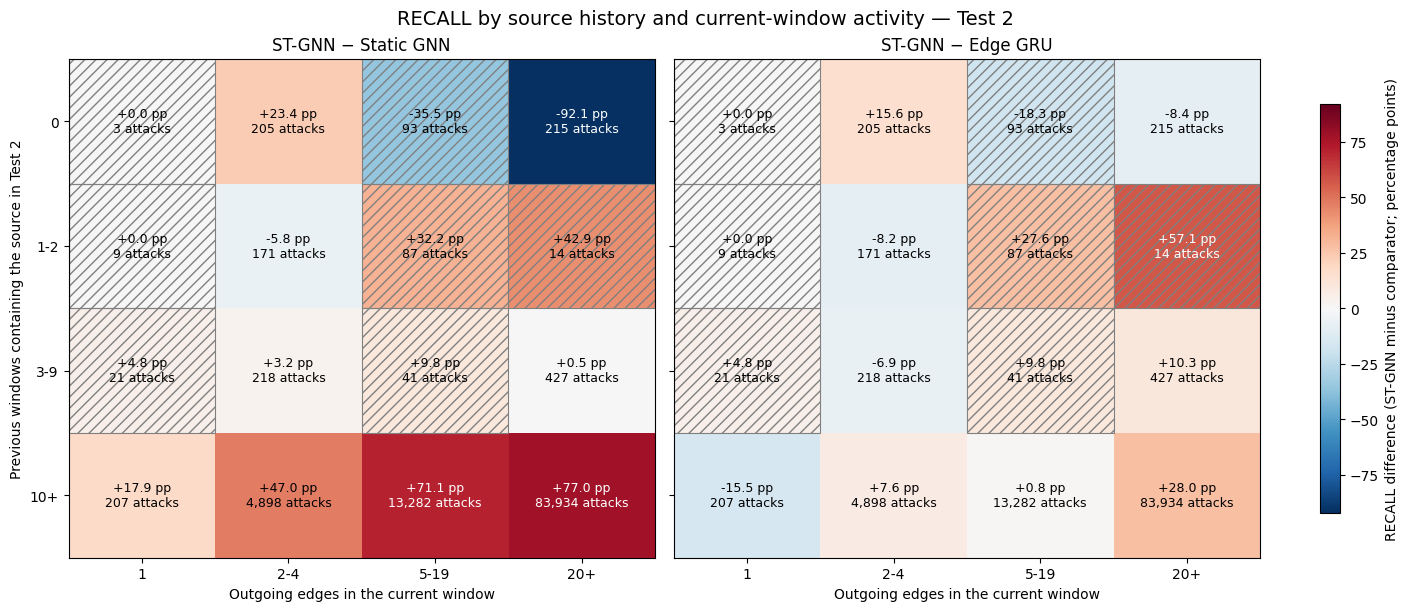

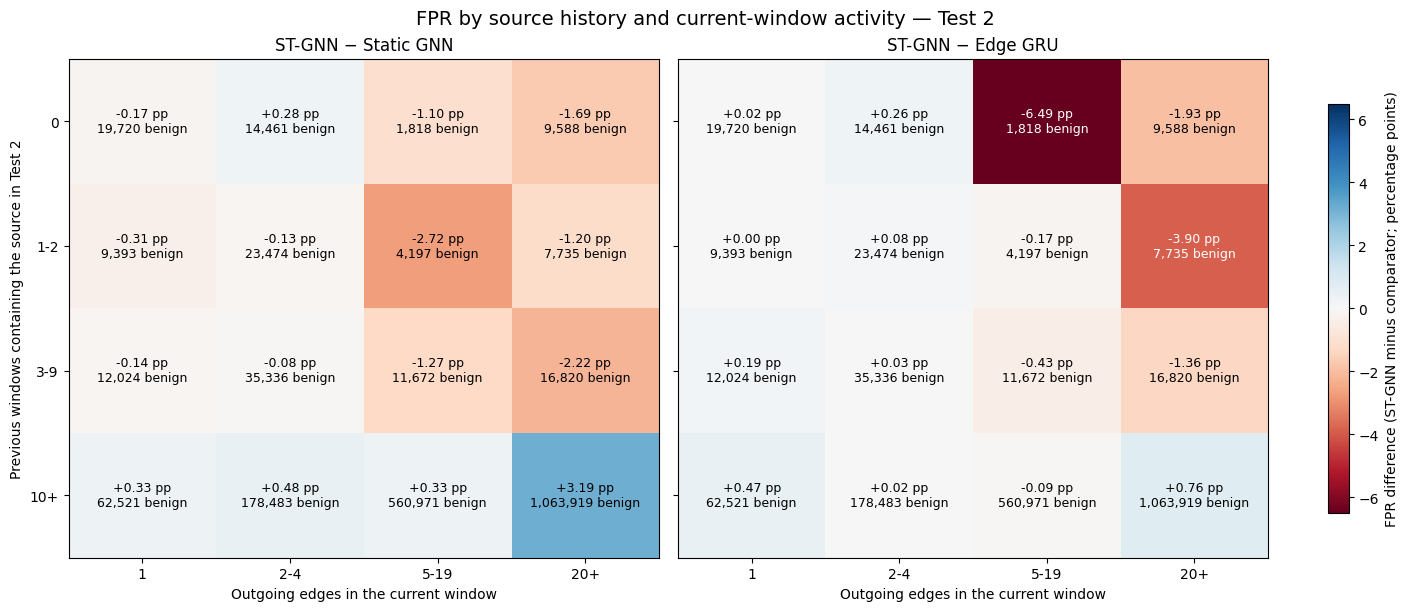

Figures saved to: /content/drive/MyDrive/nids-mitre/results_comparison/stgnn_gain_audit
Hatching marks cells with fewer than 100 flows in the relevant denominator.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle

history_order = ['0', '1-2', '3-9', '10+']
degree_order = ['1', '2-4', '5-19', '20+']

# Keep only the 16 history × degree groups.
joint = grouped.loc[
    grouped['group'].astype(str).str.contains(' / ', regex=False)
].copy()
joint[['history_bin', 'degree_bin']] = joint['group'].astype(str).str.split(
    ' / ', n=1, expand=True
)

assert len(joint) == 16
assert not joint.duplicated(['history_bin', 'degree_bin']).any()

def as_grid(column):
    return (
        joint.pivot(
            index='history_bin',
            columns='degree_bin',
            values=column,
        )
        .reindex(index=history_order, columns=degree_order)
        .to_numpy(dtype=float)
    )

plot_dir = DRIVE_ROOT / 'results_comparison' / 'stgnn_gain_audit'
plot_dir.mkdir(parents=True, exist_ok=True)

def plot_metric_differences(metric, denominator, denominator_label,
                            decimals, filename):
    # Convert rate differences to percentage points.
    differences = [
        ('Static GNN', 100 * (
            as_grid(f'ST-GNN_{metric}') -
            as_grid(f'Static GNN_{metric}')
        )),
        ('Edge GRU', 100 * (
            as_grid(f'ST-GNN_{metric}') -
            as_grid(f'Edge GRU_{metric}')
        )),
    ]
    counts = as_grid(denominator)
    all_values = np.stack([values for _, values in differences])
    color_limit = max(float(np.nanmax(np.abs(all_values))), 1e-6)

    # For recall, positive favors ST-GNN. For FPR, negative favors ST-GNN.
    cmap = 'RdBu_r' if metric == 'recall' else 'RdBu'
    norm = TwoSlopeNorm(
        vmin=-color_limit, vcenter=0, vmax=color_limit
    )

    fig, axes = plt.subplots(
        1, 2, figsize=(14, 6),
        sharex=True, sharey=True,
        constrained_layout=True,
    )

    for ax, (comparator, values) in zip(axes, differences):
        image = ax.imshow(
            values, cmap=cmap, norm=norm, aspect='auto'
        )
        ax.set_title(f'ST-GNN − {comparator}')
        ax.set_xticks(range(4), degree_order)
        ax.set_yticks(range(4), history_order)
        ax.set_xlabel('Outgoing edges in the current window')

        for row in range(4):
            for col in range(4):
                value = values[row, col]
                n = int(counts[row, col])
                color = (
                    'white'
                    if np.isfinite(value) and abs(value) > 0.55 * color_limit
                    else 'black'
                )
                value_text = (
                    f'{value:+.{decimals}f} pp'
                    if np.isfinite(value) else 'undefined'
                )
                ax.text(
                    col, row,
                    f'{value_text}\n{n:,} {denominator_label}',
                    ha='center', va='center',
                    fontsize=9, color=color,
                )

                # Small denominators are visually flagged, not excluded.
                if n < 100:
                    ax.add_patch(Rectangle(
                        (col - 0.5, row - 0.5), 1, 1,
                        fill=False, hatch='///',
                        edgecolor='gray', linewidth=0.8,
                    ))

    axes[0].set_ylabel(
        'Previous windows containing the source in Test 2'
    )
    fig.colorbar(
        image, ax=axes, shrink=0.82,
        label=f'{metric.upper()} difference '
              '(ST-GNN minus comparator; percentage points)',
    )
    fig.suptitle(
        f'{metric.upper()} by source history and current-window activity'
        ' — Test 2',
        fontsize=14,
    )

    fig.savefig(plot_dir / f'{filename}.png',
                dpi=300, bbox_inches='tight')
    fig.savefig(plot_dir / f'{filename}.pdf',
                bbox_inches='tight')
    plt.show()

# Recall denominator: attack-labeled flows in each cell.
plot_metric_differences(
    metric='recall',
    denominator='attacks',
    denominator_label='attacks',
    decimals=1,
    filename='recall_history_degree_test2',
)

# FPR denominator: benign-labeled flows in each cell.
plot_metric_differences(
    metric='FPR',
    denominator='benign',
    denominator_label='benign',
    decimals=2,
    filename='fpr_history_degree_test2',
)

print('Figures saved to:', plot_dir)
print('Hatching marks cells with fewer than 100 flows in the relevant denominator.')



## 3. Interpretation and record

If resetting memory reduces AP, this checkpoint **uses** historical state; it does not show that a retrained temporal architecture would outperform a non-temporal one. A gain over Static GNN among previously seen sources supports a historical-context hypothesis; a gain limited to high-degree sources supports an instantaneous-activity hypothesis. Check source concentration before attributing a pattern from one or two hosts to an entire campaign. A causal claim would require retraining variants without memory and without spatial message passing under the same seeds, data, and validation-selection protocol. These comparisons are diagnostic.


In [ ]:
out_dir = DRIVE_ROOT / 'results_comparison' / 'stgnn_gain_audit'
out_dir.mkdir(parents=True, exist_ok=True)
stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
summary.to_csv(out_dir / f'summary_{stamp}.csv', index=False)
pairs.to_csv(out_dir / f'paired_{stamp}.csv', index=False)
grouped.to_csv(out_dir / f'groups_{stamp}.csv', index=False)
manifest = {
    'code_commit': EXPECTED_COMMIT,
    'graph_root': str(GRAPH_ROOT / 'test2'),
    'original_labels': True,
    'threshold_operator': '>',
    'intervention': 'reset ST-GNN node memory before every nonempty graph window; no retraining',
    'runs': {name: {k: str(a[k]) for k in ('experiment','seed','run_id','checkpoint','threshold')}
             for name, a in ARTIFACTS.items()},
}
(out_dir / f'manifest_{stamp}.json').write_text(json.dumps(manifest, indent=2))
print('Results:', out_dir, '| suffix:', stamp)


Results: /content/drive/MyDrive/nids-mitre/results_comparison/stgnn_gain_audit | suffix: 20261020T192542Z


## Diagnosis by source: concentration, exclusion, and evolution by window

In [6]:
# Uses the original labels and the graph’s `global_node_ids`; it does not assign IPs or stages.
from sklearn.metrics import average_precision_score

y = RUNS['ST-GNN']['y']
gid = RUNS['ST-GNN']['meta']['source_gid']
window = RUNS['ST-GNN']['window']
st = RUNS['ST-GNN']['pred']
models = ['ST-GNN', 'Static GNN', 'Edge GRU']

assert all(len(r['p']) == len(y) for r in RUNS.values())
assert len(gid) == len(window) == len(y)

# 1. Sources of the attacks that ST-GNN detects but Edge GRU does not.
exclusive = (y == 1) & st & ~RUNS['Edge GRU']['pred']
ranking = pd.Series(gid[exclusive]).value_counts()
assert len(ranking) > 0

focus_id = int(ranking.index[0])
top10_ids = ranking.head(10).index.to_numpy()

print("Exclusive true positives versus Edge GRU:", int(exclusive.sum()))
print("Main source (global_node_id):", focus_id)
print("Proportion of those successes attributable to the main source:",
      f"{ranking.iloc[0] / ranking.sum():.2%}")
print("\nTen sources with the most unique correct answers:")
display(ranking.head(10).rename_axis('source_gid')
        .reset_index(name='ST_only_TP_vs_EdgeGRU'))

# 2. Comparison across the same subsets of flows.
def metrics_on(mask, name):
    yy = y[mask]
    pred = RUNS[name]['pred'][mask]
    prob = RUNS[name]['p'][mask]
    tp = int(((yy == 1) & pred).sum())
    fp = int(((yy == 0) & pred).sum())
    fn = int(((yy == 1) & ~pred).sum())
    tn = int(((yy == 0) & ~pred).sum())
    return {
        'model': name,
        'flows': len(yy),
        'attacks': tp + fn,
        'benign': fp + tn,
        'AP': average_precision_score(yy, prob)
              if (tp + fn) and (fp + tn) else np.nan,
        'recall': tp / (tp + fn) if tp + fn else np.nan,
        'FPR': fp / (fp + tn) if fp + tn else np.nan,
        'TP': tp,
        'FP': fp,
    }

subsets = {
    'Full Test 2': np.ones(len(y), dtype=bool),
    'Only main source': gid == focus_id,
    'Without main source': gid != focus_id,
    'Without 10 main sources': ~np.isin(gid, top10_ids),
}

rows = []
for subset_name, mask in subsets.items():
    for name in models:
        rows.append({'subset_name': subset_name, **metrics_on(mask, name)})

comparison = pd.DataFrame(rows)
print("\nMetrics by subset (same workflows for all three models):")
display(comparison.round(4))

print("\nAP from the same ST-GNN checkpoint with memory reset:")
display(pd.DataFrame([
    {
        'subset_name': subset_name,
        'AP_with_memory': metrics_on(mask, 'ST-GNN')['AP'],
        'AP_memory_reset': metrics_on(
            mask, 'ST-GNN with reset memory (intervention)')['AP'],
    }
    for subset_name, mask in subsets.items()
]).round(4))

# 3. Evolution of the primary source by window.
focus = gid == focus_id
windows, inverse = np.unique(window[focus], return_inverse=True)
yf = y[focus]
attack = yf == 1
benign = ~attack
n_windows = len(windows)

attack_count = np.bincount(inverse, weights=attack, minlength=n_windows).astype(int)
benign_count = np.bincount(inverse, weights=benign, minlength=n_windows).astype(int)

trajectory = pd.DataFrame({
    'window': windows,
    'attacks': attack_count,
    'benign': benign_count,
})

def safe_rate(numerator, denominator):
    return np.divide(
        numerator, denominator,
        out=np.full(len(denominator), np.nan, dtype=float),
        where=denominator > 0
    )

for name, prefix in [
    ('ST-GNN', 'ST'),
    ('Static GNN', 'Static'),
    ('Edge GRU', 'EdgeGRU'),
]:
    p = RUNS[name]['p'][focus]
    pred = RUNS[name]['pred'][focus]
    trajectory[f'{prefix}_recall'] = safe_rate(
        np.bincount(inverse, weights=pred & attack, minlength=n_windows),
        attack_count
    )
    trajectory[f'{prefix}_FPR'] = safe_rate(
        np.bincount(inverse, weights=pred & benign, minlength=n_windows),
        benign_count
    )
    trajectory[f'{prefix}_score_benigno'] = safe_rate(
        np.bincount(inverse, weights=p * benign, minlength=n_windows),
        benign_count
    )

attack_positions = np.flatnonzero(attack_count > 0)
print(f"\nSource {focus_id} appears in {n_windows} windows.")
print(f"Flows labeled as an attack: {attack_count.sum()}; "
      f"benign: {benign_count.sum()}.")

if len(attack_positions):
    first = attack_positions[0]
    print("\nWindows in which the source appears, surrounding their first flow labeled as an attack:")
    display(trajectory.iloc[max(0, first - 10):first + 6].round(4))

    print("\nFirst 12 windows from the source with flows labeled as an attack:")
    display(trajectory.loc[trajectory['attacks'] > 0].head(12).round(4))


Exclusive true positives versus Edge GRU: 25558
Main source (global_node_id): 1195
Proportion of those successes attributable to the main source: 87.29%

Ten sources with the most unique correct answers:


,source_gid,ST_only_TP_vs_EdgeGRU
0,1195,22310
1,1188,2418
2,1184,92
3,1211,88
4,1169,74
5,4,60
6,1156,46
7,2114,44
8,1208,36
9,1147,32



Metrics by subset (same workflows for all three models):


,subset_name,model,flows,attacks,benign,AP,recall,FPR,TP,FP
0,Full Test 2,ST-GNN,2135957,103825,2032132,0.8384,0.9419,0.0278,97793,56546
1,Full Test 2,Static GNN,2135957,103825,2032132,0.3142,0.2071,0.0102,21497,20707
2,Full Test 2,Edge GRU,2135957,103825,2032132,0.7307,0.7110,0.0243,73819,49410
3,Only main source,ST-GNN,51625,36934,14691,0.9973,0.9530,0.0012,35198,18
4,Only main source,Static GNN,51625,36934,14691,0.9716,0.1131,0.0007,4176,10
5,Only main source,Edge GRU,51625,36934,14691,0.9882,0.3526,0.0010,13024,15
6,Without main source,ST-GNN,2084332,66891,2017441,0.7495,0.9358,0.0280,62595,56528
7,Without main source,Static GNN,2084332,66891,2017441,0.2418,0.2589,0.0103,17321,20697
8,Without main source,Edge GRU,2084332,66891,2017441,0.7652,0.9089,0.0245,60795,49395
9,Without 10 main sources,ST-GNN,1981932,10921,1971011,0.5600,0.8630,0.0191,9425,37712



AP from the same ST-GNN checkpoint with memory reset:


,subset_name,AP_with_memory,AP_memory_reset
0,Full Test 2,0.8384,0.4507
1,Only main source,0.9973,0.9950
2,Without main source,0.7495,0.1152
3,Without 10 main sources,0.5600,0.0262



Source 1195 appears in 272 windows.
Flows labeled as an attack: 36934; benign: 14691.

Windows in which the source appears, surrounding their first flow labeled as an attack:


,window,attacks,benign,ST_recall,ST_FPR,ST_score_benigno,Static_recall,Static_FPR,Static_score_benigno,EdgeGRU_recall,EdgeGRU_FPR,EdgeGRU_score_benigno
0,1473,17,84,0.0,0.0,0.0668,0.0,0.0,0.2339,0.0,0.0,0.0307
1,1474,1,1,0.0,0.0,0.0000,0.0,0.0,0.0004,0.0,0.0,0.0017
2,1475,1,7,0.0,0.0,0.0248,0.0,0.0,0.0575,0.0,0.0,0.0437
3,1477,1,2,0.0,0.0,0.0164,0.0,0.0,0.0581,0.0,0.0,0.0213
4,1478,0,1,NaN,0.0,0.0001,NaN,0.0,0.0008,NaN,0.0,0.0011
5,1479,1,13,0.0,0.0,0.0302,0.0,0.0,0.0997,0.0,0.0,0.0384



First 12 windows from the source with flows labeled as an attack:


,window,attacks,benign,ST_recall,ST_FPR,ST_score_benigno,Static_recall,Static_FPR,Static_score_benigno,EdgeGRU_recall,EdgeGRU_FPR,EdgeGRU_score_benigno
0,1473,17,84,0.0,0.0,0.0668,0.0,0.0,0.2339,0.0,0.0,0.0307
1,1474,1,1,0.0,0.0,0.0000,0.0,0.0,0.0004,0.0,0.0,0.0017
2,1475,1,7,0.0,0.0,0.0248,0.0,0.0,0.0575,0.0,0.0,0.0437
3,1477,1,2,0.0,0.0,0.0164,0.0,0.0,0.0581,0.0,0.0,0.0213
5,1479,1,13,0.0,0.0,0.0302,0.0,0.0,0.0997,0.0,0.0,0.0384
6,1481,1,0,0.0,NaN,NaN,0.0,NaN,NaN,0.0,NaN,NaN
7,1482,18,60,0.0,0.0,0.0345,0.0,0.0,0.0955,0.0,0.0,0.0602
8,1483,1,0,0.0,NaN,NaN,0.0,NaN,NaN,0.0,NaN,NaN
9,1485,1,8,0.0,0.0,0.0376,0.0,0.0,0.2707,0.0,0.0,0.0571
11,1487,1,1,0.0,0.0,0.0313,0.0,0.0,0.1597,0.0,0.0,0.0628


In [7]:
from sklearn.metrics import roc_curve

print("First attack detected from source 1195 using the original threshold")
attack_1195 = (gid == focus_id) & (y == 1)

for name in models:
    hits = attack_1195 & RUNS[name]['pred']
    threshold = ARTIFACTS[name]['threshold']
    if hits.any():
        first_window = int(window[hits].min())
        missed_before = int((attack_1195 & (window < first_window)).sum())
        print(f"{name:12s} threshold={threshold:.6f}  "
              f"first_window={first_window}  "
              f"missed_attacks_before={missed_before}")
    else:
        print(f"{name:12s} threshold={threshold:.6f}  no correct answers")

print("\nMaximum recall with FPR ≤ 1% in each subset")
rows = []
for subset_name in ['Only main source', 'Without main source']:
    mask = subsets[subset_name]
    for name in models:
        fpr, tpr, thresholds = roc_curve(y[mask], RUNS[name]['p'][mask])
        eligible = np.flatnonzero(fpr <= 0.01)
        i = eligible[np.argmax(tpr[eligible])]
        rows.append({
            'subset_name': subset_name,
            'model': name,
            'recall_with_max_1pct_FPR': tpr[i],
            'FPR': fpr[i],
            'threshold': thresholds[i],
        })

display(pd.DataFrame(rows).round(4))


First attack detected from source 1195 using the original threshold
ST-GNN       threshold=0.203219  first_window=1700  missed_attacks_before=822
Static GNN   threshold=0.393601  first_window=1702  missed_attacks_before=840
Edge GRU     threshold=0.350914  first_window=1667  missed_attacks_before=477

Maximum recall with FPR ≤ 1% in each subset


,subset_name,model,recall_with_max_1pct_FPR,FPR,threshold
0,Only main source,ST-GNN,0.9570,0.0099,0.0450
1,Only main source,Static GNN,0.3315,0.0099,0.2833
2,Only main source,Edge GRU,0.9086,0.0095,0.1028
3,Without main source,ST-GNN,0.7936,0.0100,0.3466
4,Without main source,Static GNN,0.2567,0.0100,0.4003
5,Without main source,Edge GRU,0.7873,0.0100,0.6370


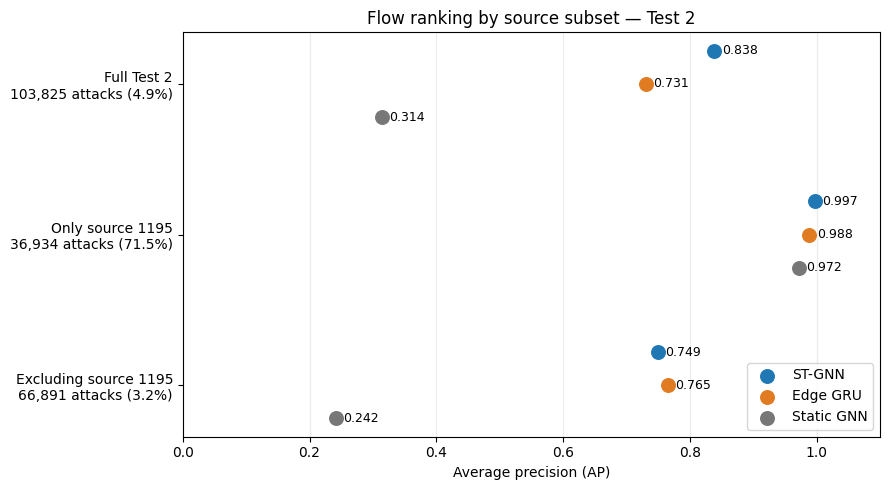

In [10]:
import numpy as np
import matplotlib.pyplot as plt

assert focus_id == 1195

subset_order = [
    'Full Test 2',
    'Only main source',
    'Without main source',
]
model_order = ['ST-GNN', 'Edge GRU', 'Static GNN']
colors = {
    'ST-GNN': '#1f77b4',
    'Edge GRU': '#e07b22',
    'Static GNN': '#777777',
}
offsets = {
    'ST-GNN': -0.22,
    'Edge GRU': 0.00,
    'Static GNN': 0.22,
}

figure_data = comparison.loc[
    comparison['subset_name'].isin(subset_order)
    & comparison['model'].isin(model_order)
].copy()

assert len(figure_data) == len(subset_order) * len(model_order)
assert not figure_data.duplicated(['subset_name', 'model']).any()

subset_names = {
    'Full Test 2': 'Full Test 2',
    'Only main source': f'Only source {focus_id}',
    'Without main source': f'Excluding source {focus_id}',
}

y_labels = []
for subset_name in subset_order:
    example = figure_data.loc[
        figure_data['subset_name'] == subset_name
    ].iloc[0]
    attacks = int(example['attacks'])
    flows = int(example['flows'])
    y_labels.append(
        f'{subset_names[subset_name]}\n'
        f'{attacks:,} attacks ({attacks / flows:.1%})'
    )

fig, ax = plt.subplots(figsize=(9, 5))

for model in model_order:
    values = [
        float(figure_data.loc[
            (figure_data['subset_name'] == subset_name)
            & (figure_data['model'] == model),
            'AP',
        ].iloc[0])
        for subset_name in subset_order
    ]
    positions = np.arange(len(subset_order)) + offsets[model]

    ax.scatter(
        values, positions,
        s=95, color=colors[model], label=model, zorder=3,
    )
    for value, position in zip(values, positions):
        ax.text(
            value + 0.012, position, f'{value:.3f}',
            va='center', fontsize=9,
        )

ax.set_yticks(np.arange(len(subset_order)), y_labels)
ax.invert_yaxis()
ax.set_xlim(0, 1.10)
ax.set_xlabel('Average precision (AP)')
ax.set_title('Flow ranking by source subset — Test 2')
ax.grid(axis='x', alpha=0.25)
ax.legend(loc='lower right')
fig.tight_layout()

figure_dir = DRIVE_ROOT / 'results_comparison' / 'stgnn_gain_audit' / 'figures'
figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_dir / 'ap_by_source_subset.png',
            dpi=300, bbox_inches='tight')
fig.savefig(figure_dir / 'ap_by_source_subset.pdf',
            bbox_inches='tight')
plt.show()

In [8]:
from sklearn.metrics import average_precision_score

compare_models = ['ST-GNN', 'Edge GRU']

# A. The same number of alerts, using the original scores.
rows = []
for subset_name, mask in {
    'Full Test 2': np.ones(len(y), dtype=bool),
    'Without source 1195': gid != focus_id,
}.items():
    indices = np.flatnonzero(mask)
    attacks_in_subset = int(y[indices].sum())

    for budget in [10_000, 50_000, 100_000]:
        for name in compare_models:
            scores = RUNS[name]['p'][indices]
            chosen_local = np.argpartition(scores, -budget)[-budget:]
            chosen = indices[chosen_local]
            tp = int(y[chosen].sum())

            rows.append({
                'subset_name': subset_name,
                'model': name,
                'alerts': budget,
                'detected_attacks': tp,
                'false_alarms': budget - tp,
                'precision': tp / budget,
                'recall': tp / attacks_in_subset,
            })

alert_budget = pd.DataFrame(rows)
print("Comparison with an equal number of alerts:")
display(alert_budget.round(4))

# B. AUC-PR by source. We request a sufficient number of examples from both classes
# to avoid drawing conclusions based on only two or three streams.
order = np.argsort(gid, kind='mergesort')
ordered_gid = gid[order]
unique_ids, starts, counts = np.unique(
    ordered_gid, return_index=True, return_counts=True
)

host_rows = []
for source_id, start, count in zip(unique_ids, starts, counts):
    idx = order[start:start + count]
    yy = y[idx]
    n_attack = int(yy.sum())
    n_benign = len(yy) - n_attack

    if n_attack < 50 or n_benign < 50:
        continue

    ap_st = average_precision_score(yy, RUNS['ST-GNN']['p'][idx])
    ap_edge = average_precision_score(yy, RUNS['Edge GRU']['p'][idx])

    host_rows.append({
        'source_gid': int(source_id),
        'attacks': n_attack,
        'benign': n_benign,
        'AP_ST': ap_st,
        'AP_EdgeGRU': ap_edge,
        'difference_ST_minus_EdgeGRU': ap_st - ap_edge,
    })

by_host = pd.DataFrame(host_rows)
print(f"\nAssessable sources: {len(by_host)}")
print(f"Covert attacks: {by_host['attacks'].sum()} de {int(y.sum())}")

if len(by_host):
    print("Sources with the most attacks:")
    display(by_host.sort_values('attacks', ascending=False).head(20).round(4))

    print("Summary giving equal weight to each evaluable source:")
    print("ST-GNN wins:",
          int((by_host['difference_ST_minus_EdgeGRU'] > 0).sum()))
    print("Edge GRU wins:",
          int((by_host['difference_ST_minus_EdgeGRU'] < 0).sum()))
    print("Average AP difference per source:",
          round(by_host['difference_ST_minus_EdgeGRU'].mean(), 4))
    print("Median difference in AP by source:",
          round(by_host['difference_ST_minus_EdgeGRU'].median(), 4))

Comparison with an equal number of alerts:


,subset_name,model,alerts,detected_attacks,false_alarms,precision,recall
0,Full Test 2,ST-GNN,10000,9243,757,0.9243,0.0890
1,Full Test 2,Edge GRU,10000,8868,1132,0.8868,0.0854
2,Full Test 2,ST-GNN,50000,45010,4990,0.9002,0.4335
3,Full Test 2,Edge GRU,50000,41140,8860,0.8228,0.3962
4,Full Test 2,ST-GNN,100000,82182,17818,0.8218,0.7915
5,Full Test 2,Edge GRU,100000,69194,30806,0.6919,0.6664
6,Without source 1195,ST-GNN,10000,8509,1491,0.8509,0.1272
7,Without source 1195,Edge GRU,10000,8479,1521,0.8479,0.1268
8,Without source 1195,ST-GNN,50000,39911,10089,0.7982,0.5967
9,Without source 1195,Edge GRU,50000,40572,9428,0.8114,0.6065



Assessable sources: 18
Covert attacks: 102150 de 103825
Sources with the most attacks:


,source_gid,attacks,benign,AP_ST,AP_EdgeGRU,difference_ST_minus_EdgeGRU
9,1195,36934,14691,0.9973,0.9882,0.0091
11,1211,8888,3144,0.8484,0.8520,-0.0036
3,1147,8232,3544,0.8149,0.8161,-0.0012
5,1169,8088,3616,0.8128,0.8216,-0.0088
7,1188,7472,3398,0.8253,0.8340,-0.0087
8,1191,7390,3304,0.8258,0.8305,-0.0047
4,1156,6850,3248,0.7763,0.8059,-0.0296
6,1184,6618,2684,0.8420,0.8406,0.0014
14,2114,4640,399,0.9703,0.9747,-0.0044
10,1208,3799,2360,0.7564,0.7747,-0.0182


Summary giving equal weight to each evaluable source:
ST-GNN wins: 4
Edge GRU wins: 13
Average AP difference per source: -0.0129
Median difference in AP by source: -0.0067


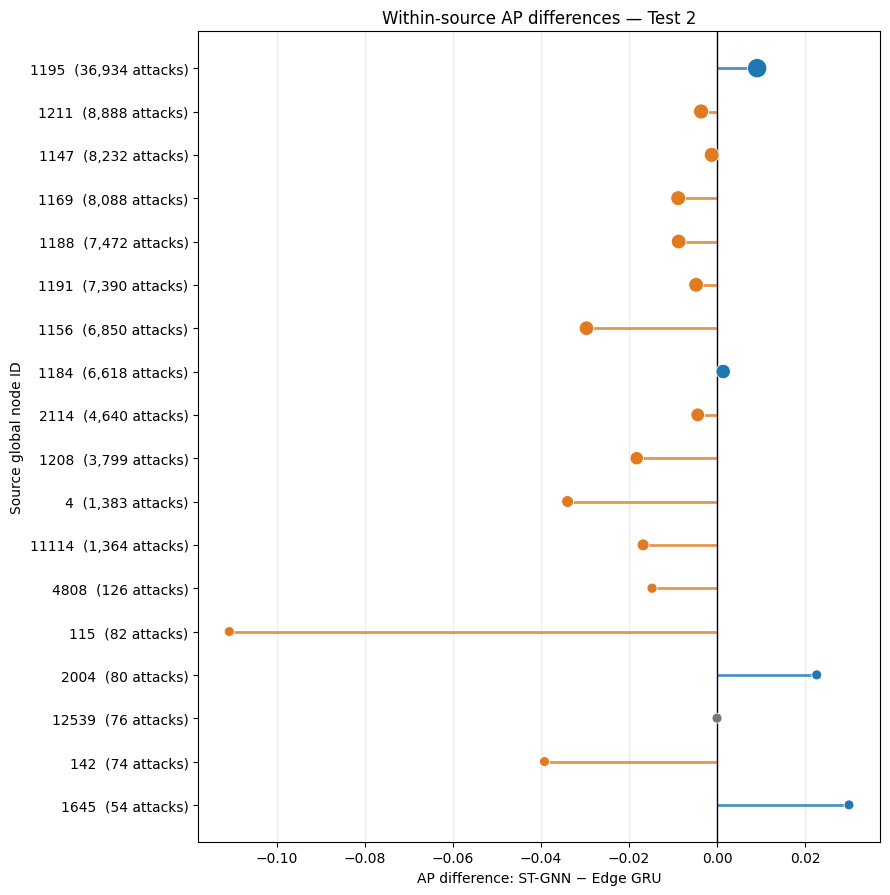

Plotted 18 sources with at least 50 attack and 50 benign flows each.


In [14]:
import numpy as np
import matplotlib.pyplot as plt

required = {
    'source_gid', 'attacks',
    'difference_ST_minus_EdgeGRU',
}
assert required.issubset(by_host.columns)

host_data = (
    by_host.sort_values('attacks', ascending=False)
    .reset_index(drop=True)
)
assert len(host_data) > 0

differences = host_data['difference_ST_minus_EdgeGRU'].to_numpy()
attack_counts = host_data['attacks'].to_numpy()
positions = np.arange(len(host_data))

colors = np.where(
    differences > 0, '#1f77b4',
    np.where(differences < 0, '#e07b22', '#777777'),
)
sizes = 45 + 150 * np.sqrt(attack_counts / attack_counts.max())

fig_height = max(5.5, 0.42 * len(host_data) + 1.5)
fig, ax = plt.subplots(figsize=(9, fig_height))

ax.hlines(
    positions, 0, differences,
    colors=colors, linewidth=2, alpha=0.8,
)
ax.scatter(
    differences, positions,
    s=sizes, c=colors, zorder=3,
    edgecolor='white', linewidth=0.6,
)
ax.axvline(0, color='black', linewidth=1)

labels = [
    f'{int(source)}  ({int(attacks):,} attacks)'
    for source, attacks in zip(
        host_data['source_gid'], attack_counts
    )
]
ax.set_yticks(positions, labels)
ax.invert_yaxis()
ax.set_xlabel('AP difference: ST-GNN − Edge GRU')
ax.set_ylabel('Source global node ID')
ax.set_title('Within-source AP differences — Test 2')
ax.grid(axis='x', alpha=0.25)
fig.tight_layout()

figure_dir = DRIVE_ROOT / 'results_comparison' / 'stgnn_gain_audit' / 'figures'
figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_dir / 'ap_difference_by_source.png',
            dpi=300, bbox_inches='tight')
fig.savefig(figure_dir / 'ap_difference_by_source.pdf',
            bbox_inches='tight')
plt.show()

print(
    f'Plotted {len(host_data)} sources with at least '
    '50 attack and 50 benign flows each.'
)


In [9]:
rows = []

for budget in [10_000, 50_000, 100_000]:
    for name in ['ST-GNN', 'Edge GRU']:
        scores = RUNS[name]['p']
        selected = np.argpartition(scores, -budget)[-budget:]

        from_1195 = gid[selected] == focus_id
        positive = y[selected] == 1

        rows.append({
            'model': name,
            'total_alerts_(budget)': budget,
            'alerts_1195': int(from_1195.sum()),
            'attacks_1195': int((from_1195 & positive).sum()),
            'false_alarms_1195': int((from_1195 & ~positive).sum()),
            'remaining_alerts': int((~from_1195).sum()),
            'remaining_attacks': int((~from_1195 & positive).sum()),
            'remaining_false_alarms': int((~from_1195 & ~positive).sum()),
        })

display(pd.DataFrame(rows))

,model,total_alerts_(budget),alerts_1195,attacks_1195,false_alarms_1195,remaining_alerts,remaining_attacks,remaining_false_alarms
0,ST-GNN,10000,5596,5582,14,4404,3661,743
1,Edge GRU,10000,2182,2180,2,7818,6688,1130
2,ST-GNN,50000,22593,22577,16,27407,22433,4974
3,Edge GRU,50000,2890,2882,8,47110,38258,8852
4,ST-GNN,100000,30025,30007,18,69975,52175,17800
5,Edge GRU,100000,12015,12004,11,87985,57190,30795


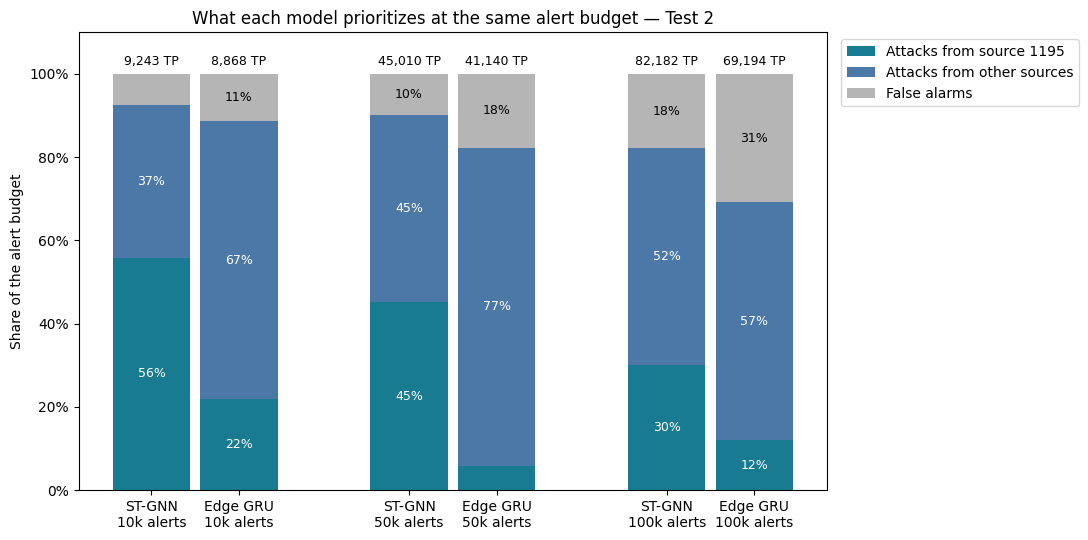

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

assert focus_id == 1195

budget_data = pd.DataFrame(rows).rename(columns={
    'total_alerts_(budget)': 'alerts',
    'remaining_attacks': 'attacks_other',
    'remaining_false_alarms': 'false_alarms_other',
})

budgets = [10_000, 50_000, 100_000]
models = ['ST-GNN', 'Edge GRU']
assert len(budget_data) == len(budgets) * len(models)

segments = [
    ('Attacks from source 1195', 'attacks_1195', '#187b91'),
    ('Attacks from other sources', 'attacks_other', '#4c78a8'),
    ('False alarms', 'false_alarms', '#b5b5b5'),
]

budget_data['false_alarms'] = (
    budget_data['false_alarms_1195']
    + budget_data['false_alarms_other']
)
assert (
    budget_data['attacks_1195']
    + budget_data['attacks_other']
    + budget_data['false_alarms']
    == budget_data['alerts']
).all()

fig, ax = plt.subplots(figsize=(11, 5.5))
tick_positions = []
tick_labels = []

for budget_index, budget in enumerate(budgets):
    for model_index, model in enumerate(models):
        row = budget_data.loc[
            (budget_data['alerts'] == budget)
            & (budget_data['model'] == model)
        ].iloc[0]

        x = budget_index * 2.5 + model_index * 0.85
        bottom = 0.0

        for label, column, color in segments:
            fraction = int(row[column]) / budget
            ax.bar(
                x, fraction, width=0.75, bottom=bottom,
                color=color,
                label=label if budget_index == model_index == 0 else None,
            )
            if fraction >= 0.08:
                ax.text(
                    x, bottom + fraction / 2,
                    f'{fraction:.0%}',
                    ha='center', va='center',
                    fontsize=9,
                    color='black' if column == 'false_alarms' else 'white',
                )
            bottom += fraction

        true_positives = (
            int(row['attacks_1195']) + int(row['attacks_other'])
        )
        ax.text(
            x, 1.015, f'{true_positives:,} TP',
            ha='center', va='bottom', fontsize=9,
        )

        tick_positions.append(x)
        tick_labels.append(f'{model}\n{budget // 1000}k alerts')

ax.set_xticks(tick_positions, tick_labels)
ax.set_ylim(0, 1.10)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel('Share of the alert budget')
ax.set_title('What each model prioritizes at the same alert budget — Test 2')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
fig.tight_layout()

figure_dir = DRIVE_ROOT / 'results_comparison' / 'stgnn_gain_audit' / 'figures'
figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_dir / 'equal_alert_budget_composition.png',
            dpi=300, bbox_inches='tight')
fig.savefig(figure_dir / 'equal_alert_budget_composition.pdf',
            bbox_inches='tight')
plt.show()
